In [4]:

import pandas as pd
import numpy as np

file_path = r"C:\Users\Lenovo\OneDrive\Documents\Financial_Analytics_Risk_System\accepted_2007_to_2018Q4.csv.gz"

df = pd.read_csv(
    file_path,
    nrows=100000,
    low_memory=False
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Rows: 100000
Columns: 151


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:

import pandas as pd
import numpy as np
import os

print("FINANCIAL ANALYTICS & RISK REPORTING SYSTEM")
print("=" * 55)

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("Environment ready!")




FINANCIAL ANALYTICS & RISK REPORTING SYSTEM
Pandas version: 3.1.1
NumPy version: 2.5.5
Environment ready!


In [4]:

file_path = r"C:\Users\Lenovo\OneDrive\Documents\Financial_Analytics_Risk_System\accepted_2007_to_2018Q4.csv.gz"

df = pd.read_csv(file_path, nrows=100000)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Rows: 100000
Columns: 151


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_23188\280153493.py:3: DtypeWarning: Columns (19: desc) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, nrows=100000)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nLOAN STATUS DISTRIBUTION")
display(df["loan_status"].value_counts())

print("\nFIRST 15 COLUMNS")
print(df.columns[:15].tolist())

print("\nMISSING VALUES")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .head(15)
)


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 151 entries, id to settlement_term
dtypes: float64(114), int64(1), str(36)
memory usage: 136.4 MB

LOAN STATUS DISTRIBUTION


loan_status
Fully Paid            70288
Charged Off           17603
Current               11402
Late (31-120 days)      441
In Grace Period         199
Late (16-30 days)        66
Default                   1
Name: count, dtype: int64


FIRST 15 COLUMNS
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status']

MISSING VALUES


member_id                              100000
sec_app_num_rev_accts                  100000
sec_app_open_act_il                    100000
sec_app_inq_last_6mths                 100000
sec_app_open_acc                       100000
sec_app_mort_acc                       100000
sec_app_mths_since_last_major_derog    100000
sec_app_collections_12_mths_ex_med     100000
sec_app_chargeoff_within_12_mths       100000
sec_app_fico_range_low                 100000
sec_app_earliest_cr_line               100000
sec_app_revol_util                     100000
sec_app_fico_range_high                100000
revol_bal_joint                        100000
desc                                    99993
dtype: int64

In [7]:


resolved_statuses = ["Fully Paid", "Charged Off", "Default"]

risk_df = df[df["loan_status"].isin(resolved_statuses)].copy()
risk_df["default_flag"] = (
    risk_df["loan_status"].isin(["Charged Off", "Default"])
).astype(int)

print("CREDIT RISK DATASET")
print("=" * 45)

print("Total resolved loans:", len(risk_df))
print("Default loans:", risk_df["default_flag"].sum())
print("Fully paid loans:", (risk_df["default_flag"] == 0).sum())

print(
    "Default rate:",
    round(risk_df["default_flag"].mean() * 100, 2),
    "%"
)

display(risk_df[[
    "loan_amnt",
    "funded_amnt",
    "int_rate",
    "annual_inc",
    "dti",
    "loan_status",
    "default_flag"
]].head(10))


CREDIT RISK DATASET
Total resolved loans: 87892
Default loans: 17604
Fully paid loans: 70288
Default rate: 20.03 %


,loan_amnt,funded_amnt,int_rate,annual_inc,dti,loan_status,default_flag
0,3600.0,3600.0,13.99,55000.0,5.91,Fully Paid,0
1,24700.0,24700.0,11.99,65000.0,16.06,Fully Paid,0
2,20000.0,20000.0,10.78,63000.0,10.78,Fully Paid,0
4,10400.0,10400.0,22.45,104433.0,25.37,Fully Paid,0
5,11950.0,11950.0,13.44,34000.0,10.20,Fully Paid,0
6,20000.0,20000.0,9.17,180000.0,14.67,Fully Paid,0
7,20000.0,20000.0,8.49,85000.0,17.61,Fully Paid,0
8,10000.0,10000.0,6.49,85000.0,13.07,Fully Paid,0
9,8000.0,8000.0,11.48,42000.0,34.80,Fully Paid,0
12,1400.0,1400.0,12.88,64000.0,34.95,Fully Paid,0


In [8]:


grade_analysis = (
    df.groupby("grade")
      .agg(
          total_loans=("id", "count"),
          total_funded=("funded_amnt", "sum"),
          average_loan=("loan_amnt", "mean"),
          average_interest=("int_rate", "mean")
      )
      .round(2)
      .sort_index()
)

display(grade_analysis)


,total_loans,total_funded,average_loan,average_interest
grade,,,,
A,17493,257728950.0,14733.26,6.82
B,30772,420216375.0,13655.80,9.97
C,29198,434504300.0,14881.30,13.15
D,13344,218693775.0,16388.92,16.71
E,6951,130762800.0,18812.08,19.11
F,1849,36515975.0,19749.04,23.44
G,393,7163925.0,18228.82,27.51


Matplotlib is building the font cache; this may take a moment.


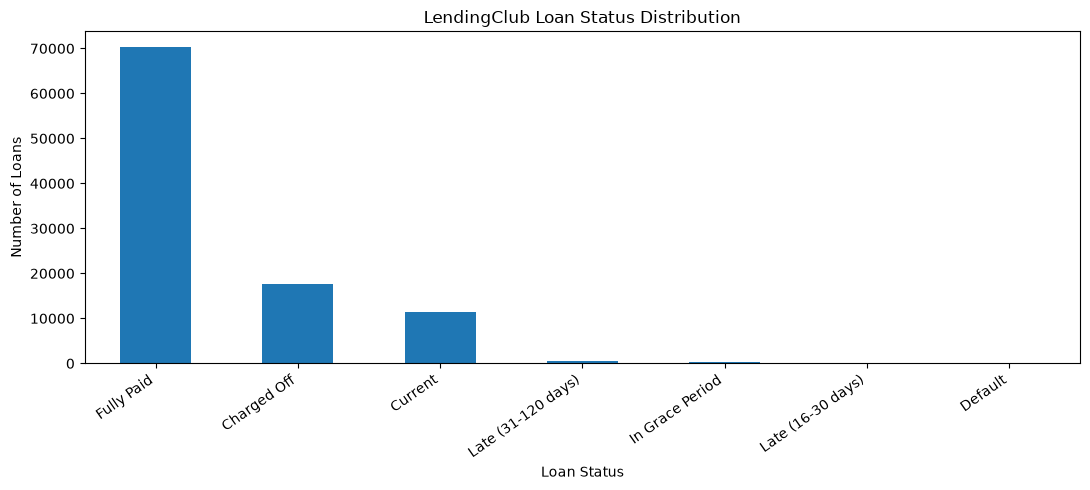

In [9]:

import matplotlib.pyplot as plt

status_counts = df["loan_status"].value_counts()

plt.figure(figsize=(11, 5))
status_counts.plot(kind="bar")

plt.title("LendingClub Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [10]:


grade_risk = (
    risk_df.groupby("grade")
    .agg(
        total_loans=("id", "count"),
        default_loans=("default_flag", "sum"),
        total_funded=("funded_amnt", "sum"),
        average_interest=("int_rate", "mean")
    )
)

grade_risk["default_rate"] = (
    grade_risk["default_loans"] /
    grade_risk["total_loans"] * 100
)

grade_risk = grade_risk.round(2)

display(grade_risk)


,total_loans,default_loans,total_funded,average_interest,default_rate
grade,,,,,
A,17059,907,249464325.0,6.80,5.32
B,28027,3699,364748700.0,9.97,13.20
C,24487,5803,342863075.0,13.13,23.70
D,10951,3776,170316200.0,16.71,34.48
E,5499,2411,100336325.0,19.11,43.84
F,1532,809,29755575.0,23.44,52.81
G,337,199,6079800.0,27.52,59.05


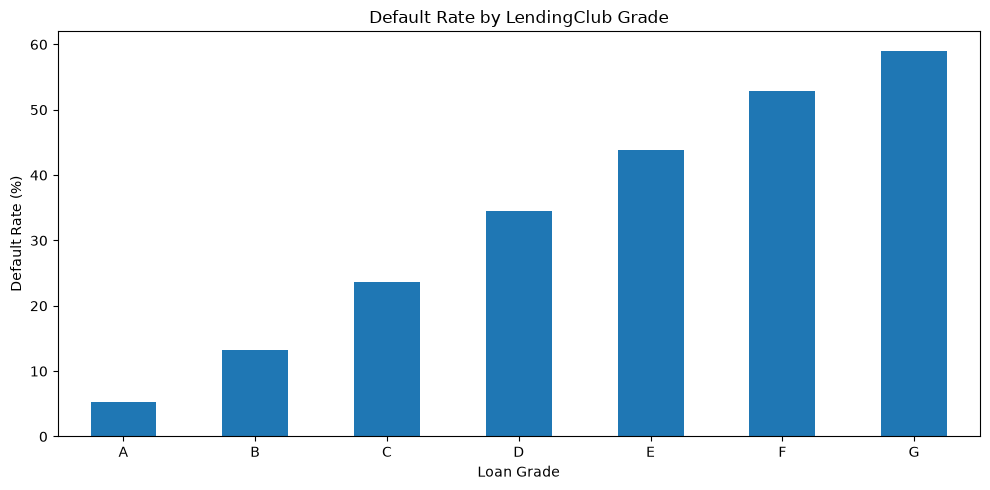

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

grade_risk["default_rate"].plot(
    kind="bar",
    title="Default Rate by LendingClub Grade"
)

plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [6]:

selected_columns = [
    "id", "loan_amnt", "funded_amnt", "funded_amnt_inv",
    "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc",
    "verification_status", "issue_d", "loan_status",
    "purpose", "addr_state", "dti", "delinq_2yrs",
    "fico_range_low", "fico_range_high", "open_acc",
    "pub_rec", "revol_bal", "revol_util", "total_acc"
]

available_columns = [
    col for col in selected_columns if col in df.columns
]

print("Available columns:", len(available_columns))


Available columns: 26


In [7]:

portfolio_df = df[available_columns].copy()

portfolio_df["default_flag"] = (
    portfolio_df["loan_status"].map({
        "Fully Paid": 0,
        "Charged Off": 1,
        "Default": 1
    })
)

portfolio_df = portfolio_df.drop_duplicates(subset=["id"])

print("Portfolio dataset ready!")
print("Total loans:", len(portfolio_df))

display(portfolio_df.head())


Portfolio dataset ready!
Total loans: 100000


,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_length,...,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc,default_flag
0,68407277,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,10+ years,...,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0,0.0
1,68355089,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,10+ years,...,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0,0.0
2,68341763,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,10+ years,...,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0,0.0
3,66310712,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,10+ years,...,17.06,0.0,785.0,789.0,13.0,0.0,7802.0,11.6,17.0,NaN
4,68476807,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,3 years,...,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0,0.0


In [13]:


clean_df = clean_df.drop_duplicates(subset=["id"])


for col in ["int_rate", "revol_util"]:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(
            clean_df[col].astype(str).str.replace("%", "", regex=False),
            errors="coerce"
        )


if "term" in clean_df.columns:
    clean_df["term"] = pd.to_numeric(
        clean_df["term"].astype(str).str.extract(r"(\d+)")[0],
        errors="coerce"
    )


if "issue_d" in clean_df.columns:
    clean_df["issue_d"] = pd.to_datetime(
        clean_df["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )


numeric_columns = [
    "loan_amnt", "funded_amnt", "funded_amnt_inv",
    "installment", "annual_inc", "dti",
    "delinq_2yrs", "fico_range_low", "fico_range_high",
    "open_acc", "pub_rec", "revol_bal", "total_acc"
]

for col in numeric_columns:
    if col in clean_df.columns:
        clean_df[col] = pd.to_numeric(
            clean_df[col], errors="coerce"
        )

print("Data type conversion completed.")
print("Duplicate IDs remaining:", clean_df["id"].duplicated().sum())

display(clean_df.dtypes)


Data type conversion completed.
Duplicate IDs remaining: 0


id                              int64
loan_amnt                     float64
funded_amnt                   float64
funded_amnt_inv               float64
term                            int64
int_rate                      float64
installment                   float64
grade                             str
sub_grade                         str
emp_length                        str
home_ownership                    str
annual_inc                    float64
verification_status               str
issue_d                datetime64[us]
loan_status                       str
purpose                           str
addr_state                        str
dti                           float64
delinq_2yrs                   float64
fico_range_low                float64
fico_range_high               float64
open_acc                      float64
pub_rec                       float64
revol_bal                     float64
revol_util                    float64
total_acc                     float64
dtype: objec

In [15]:

quality_report = pd.DataFrame({
    "Data_Type": clean_df.dtypes.astype(str),
    "Missing_Count": clean_df.isnull().sum(),
    "Missing_Percentage": (
        clean_df.isnull().mean() * 100
    ).round(2),
    "Unique_Values": clean_df.nunique()
})

display(
    quality_report.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
emp_length,str,5629,6.40,11
revol_util,float64,36,0.04,1110
loan_amnt,float64,0,0.00,1344
funded_amnt,float64,0,0.00,1344
term,int64,0,0.00,2
funded_amnt_inv,float64,0,0.00,1347
int_rate,float64,0,0.00,81
installment,float64,0,0.00,16567
grade,str,0,0.00,7
id,int64,0,0.00,87892


In [16]:

import os

os.makedirs("data/processed", exist_ok=True)

output_path = "data/processed/lendingclub_cleaned_sample.csv"

clean_df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")
print("File:", output_path)
print("Records:", len(clean_df))
print("Columns:", len(clean_df.columns))


Cleaned dataset saved successfully!
File: data/processed/lendingclub_cleaned_sample.csv
Records: 87892
Columns: 26


In [8]:


portfolio_df = df[available_columns].copy()


portfolio_df["default_flag"] = (
    portfolio_df["loan_status"].map({
        "Fully Paid": 0,
        "Charged Off": 1,
        "Default": 1
    })
)

portfolio_df = portfolio_df.drop_duplicates(subset=["id"])

portfolio_df["int_rate"] = pd.to_numeric(
    portfolio_df["int_rate"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)

portfolio_df["term"] = pd.to_numeric(
    portfolio_df["term"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

portfolio_df["issue_d"] = pd.to_datetime(
    portfolio_df["issue_d"],
    format="%b-%Y",
    errors="coerce"
)

print("Portfolio dataset ready!")
print("Total loans:", len(portfolio_df))
print("\nLoan status:")
display(portfolio_df["loan_status"].value_counts())

print("\nDefault indicator:")
display(portfolio_df["default_flag"].value_counts(dropna=False))


Portfolio dataset ready!
Total loans: 100000

Loan status:


loan_status
Fully Paid            70288
Charged Off           17603
Current               11402
Late (31-120 days)      441
In Grace Period         199
Late (16-30 days)        66
Default                   1
Name: count, dtype: int64


Default indicator:


default_flag
0.0    70288
1.0    17604
NaN    12108
Name: count, dtype: int64

In [9]:
%pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


In [11]:

from sqlalchemy import create_engine, text, URL
from getpass import getpass

mysql_user = input("Enter MySQL username (usually root): ")
mysql_password = getpass("Enter MySQL password: ")

server_url = URL.create(
    "mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host="localhost",
    port=3306
)

server_engine = create_engine(server_url)

with server_engine.connect() as connection:
    connection.execute(
        text("CREATE DATABASE IF NOT EXISTS financial_risk_db")
    )

db_url = URL.create(
    "mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host="localhost",
    port=3306,
    database="financial_risk_db"
)

engine = create_engine(db_url)

print("MySQL connected successfully!")
print("Database: financial_risk_db")


Enter MySQL username (usually root):  root
Enter MySQL password:  ········


MySQL connected successfully!
Database: financial_risk_db


In [13]:
print("Rows to upload:", len(portfolio_df))
print("Columns:", len(portfolio_df.columns))

upload_df = portfolio_df.copy()

if "id" in upload_df.columns:
    upload_df["id"] = upload_df["id"].astype("string")

# Upload to MySQL
upload_df.to_sql(
    name="loans",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
)

print("Loans table created and data uploaded successfully!")

Rows to upload: 100000
Columns: 27
Loans table created and data uploaded successfully!


In [14]:
check = pd.read_sql(
    "SELECT COUNT(*) AS total_loans FROM loans",
    engine
)

display(check)

,total_loans
0,100000


In [15]:
sample = pd.read_sql(
    "SELECT * FROM loans LIMIT 5",
    engine
)

display(sample)

,id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_length,...,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc,default_flag
0,68407277,3600.0,3600.0,3600.0,36,13.99,123.03,C,C4,10+ years,...,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0,0.0
1,68355089,24700.0,24700.0,24700.0,36,11.99,820.28,C,C1,10+ years,...,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0,0.0
2,68341763,20000.0,20000.0,20000.0,60,10.78,432.66,B,B4,10+ years,...,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0,0.0
3,66310712,35000.0,35000.0,35000.0,60,14.85,829.90,C,C5,10+ years,...,17.06,0.0,785.0,789.0,13.0,0.0,7802.0,11.6,17.0,NaN
4,68476807,10400.0,10400.0,10400.0,60,22.45,289.91,F,F1,3 years,...,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0,0.0


In [16]:
portfolio_summary = pd.read_sql("""
    SELECT
        COUNT(*) AS total_loans,
        ROUND(SUM(loan_amnt), 2) AS total_loan_amount,
        ROUND(AVG(loan_amnt), 2) AS average_loan_amount,
        ROUND(AVG(int_rate), 2) AS average_interest_rate,
        COUNT(DISTINCT grade) AS total_credit_grades
    FROM loans
""", engine)

display(portfolio_summary)

,total_loans,total_loan_amount,average_loan_amount,average_interest_rate,total_credit_grades
0,100000,1.505586e+09,15055.86,12.2,7


In [17]:
loan_status_analysis = pd.read_sql("""
    SELECT
        loan_status,
        COUNT(*) AS loan_count,
        ROUND(AVG(loan_amnt), 2) AS average_loan_amount
    FROM loans
    GROUP BY loan_status
    ORDER BY loan_count DESC
""", engine)

display(loan_status_analysis)

,loan_status,loan_count,average_loan_amount
0,Fully Paid,70288,14065.02
1,Charged Off,17603,15618.18
2,Current,11402,20039.01
3,Late (31-120 days),441,18700.96
4,In Grace Period,199,20337.56
5,Late (16-30 days),66,18833.71
6,Default,1,35000.00


In [18]:
grade_risk = pd.read_sql("""
    SELECT
        grade,
        COUNT(*) AS total_loans,

        SUM(CASE
            WHEN loan_status = 'Fully Paid' THEN 1
            ELSE 0
        END) AS fully_paid,

        SUM(CASE
            WHEN loan_status IN ('Charged Off', 'Default') THEN 1
            ELSE 0
        END) AS defaults,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN 1 ELSE 0
                END
            ) /
            NULLIF(SUM(
                CASE
                    WHEN loan_status IN (
                        'Fully Paid', 'Charged Off', 'Default'
                    )
                    THEN 1 ELSE 0
                END
            ), 0),
            2
        ) AS default_rate

    FROM loans
    GROUP BY grade
    ORDER BY grade
""", engine)

display(grade_risk)

,grade,total_loans,fully_paid,defaults,default_rate
0,A,17493,16152.0,907.0,5.32
1,B,30772,24328.0,3699.0,13.20
2,C,29198,18684.0,5803.0,23.70
3,D,13344,7175.0,3776.0,34.48
4,E,6951,3088.0,2411.0,43.84
5,F,1849,723.0,809.0,52.81
6,G,393,138.0,199.0,59.05


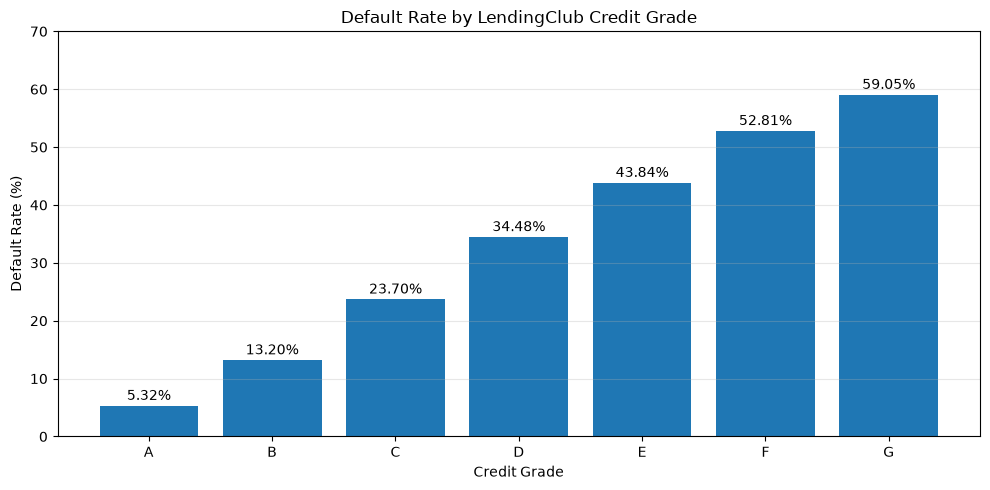

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    grade_risk["grade"],
    grade_risk["default_rate"]
)

plt.title("Default Rate by LendingClub Credit Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Default Rate (%)")

plt.ylim(0, 70)
plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(grade_risk["default_rate"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [20]:
model_df = portfolio_df[
    portfolio_df["loan_status"].isin(
        ["Fully Paid", "Charged Off", "Default"]
    )
].copy()

model_df["default_flag"] = (
    model_df["loan_status"]
    .isin(["Charged Off", "Default"])
    .astype(int)
)

candidate_features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc"
]

features = [
    col for col in candidate_features
    if col in model_df.columns
]

print("Total resolved loans:", len(model_df))
print("Available model features:", features)

print("\nTarget distribution:")
display(model_df["default_flag"].value_counts())

Total resolved loans: 87892
Available model features: ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti', 'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc']

Target distribution:


default_flag
0    70288
1    17604
Name: count, dtype: int64

In [21]:
print("Issue date available:", "issue_d" in model_df.columns)

display(model_df[features].dtypes)

missing_summary = (
    model_df[features]
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary[missing_summary > 0])

display(model_df[features + ["default_flag"]].head())

Issue date available: True


loan_amnt              float64
term                     int64
int_rate               float64
installment            float64
grade                      str
sub_grade                  str
emp_length                 str
home_ownership             str
annual_inc             float64
verification_status        str
purpose                    str
dti                    float64
delinq_2yrs            float64
fico_range_low         float64
fico_range_high        float64
open_acc               float64
pub_rec                float64
revol_bal              float64
revol_util             float64
total_acc              float64
dtype: object

emp_length    5629
revol_util      36
dti              2
dtype: int64

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,dti,delinq_2yrs,fico_range_low,fico_range_high,open_acc,pub_rec,revol_bal,revol_util,total_acc,default_flag
0,3600.0,36,13.99,123.03,C,C4,10+ years,MORTGAGE,55000.0,Not Verified,...,5.91,0.0,675.0,679.0,7.0,0.0,2765.0,29.7,13.0,0
1,24700.0,36,11.99,820.28,C,C1,10+ years,MORTGAGE,65000.0,Not Verified,...,16.06,1.0,715.0,719.0,22.0,0.0,21470.0,19.2,38.0,0
2,20000.0,60,10.78,432.66,B,B4,10+ years,MORTGAGE,63000.0,Not Verified,...,10.78,0.0,695.0,699.0,6.0,0.0,7869.0,56.2,18.0,0
4,10400.0,60,22.45,289.91,F,F1,3 years,MORTGAGE,104433.0,Source Verified,...,25.37,1.0,695.0,699.0,12.0,0.0,21929.0,64.5,35.0,0
5,11950.0,36,13.44,405.18,C,C3,4 years,RENT,34000.0,Source Verified,...,10.20,0.0,690.0,694.0,5.0,0.0,8822.0,68.4,6.0,0


In [22]:
print("Issue date examples:")
display(model_df["issue_d"].head(10))

print("\nIssue date data type:")
print(model_df["issue_d"].dtype)

print("\nEarliest issue date:")
print(model_df["issue_d"].min())

print("\nLatest issue date:")
print(model_df["issue_d"].max())

print("\nMissing issue dates:")
print(model_df["issue_d"].isna().sum())

Issue date examples:


0    2015-12-01
1    2015-12-01
2    2015-12-01
4    2015-12-01
5    2015-12-01
6    2015-12-01
7    2015-12-01
8    2015-12-01
9    2015-12-01
12   2015-12-01
Name: issue_d, dtype: datetime64[us]


Issue date data type:
datetime64[us]

Earliest issue date:
2015-10-01 00:00:00

Latest issue date:
2015-12-01 00:00:00

Missing issue dates:
0


In [23]:
model_df["issue_month"] = (
    model_df["issue_d"].dt.to_period("M").astype(str)
)

monthly_summary = (
    model_df.groupby("issue_month")
    .agg(
        total_loans=("default_flag", "count"),
        defaults=("default_flag", "sum"),
        default_rate=("default_flag", "mean")
    )
    .reset_index()
)

monthly_summary["default_rate"] *= 100
monthly_summary["default_rate"] = (
    monthly_summary["default_rate"].round(2)
)

display(monthly_summary)

,issue_month,total_loans,defaults,default_rate
0,2015-10,16133,2959,18.34
1,2015-11,32756,6508,19.87
2,2015-12,39003,8137,20.86


In [24]:
print("Unique issue dates:", model_df["issue_d"].nunique())
print("Earliest:", model_df["issue_d"].min())
print("Latest:", model_df["issue_d"].max())

Unique issue dates: 3
Earliest: 2015-10-01 00:00:00
Latest: 2015-12-01 00:00:00


In [25]:
import numpy as np
import pandas as pd

latest_month = model_df["issue_d"].dt.to_period("M").max()

train_df = model_df[
    model_df["issue_d"].dt.to_period("M") < latest_month
].copy()

test_df = model_df[
    model_df["issue_d"].dt.to_period("M") == latest_month
].copy()

X_train = train_df[features].copy()
X_test = test_df[features].copy()

y_train = train_df["default_flag"]
y_test = test_df["default_flag"]

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("Training month:", train_df["issue_d"].min(),
      "to", train_df["issue_d"].max())

print("Testing month:", latest_month)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining default rate:", round(y_train.mean() * 100, 2), "%")
print("Testing default rate:", round(y_test.mean() * 100, 2), "%")

Training month: 2015-10-01 00:00:00 to 2015-11-01 00:00:00
Testing month: 2015-12

Training records: 48889
Testing records: 39003

Training default rate: 19.36 %
Testing default rate: 20.86 %


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Preprocessing pipeline created!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created!
Numerical features: 14
Categorical features: 6


In [27]:
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("ACCURACY:", round(accuracy_score(y_test, y_pred), 4))
print("PRECISION:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("RECALL:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 SCORE:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ACCURACY: 0.6601
PRECISION: 0.3433
RECALL: 0.6891
F1 SCORE: 0.4582
ROC-AUC: 0.7369

Confusion Matrix:
[[20138 10728]
 [ 2530  5607]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.65      0.75     30866
           1       0.34      0.69      0.46      8137

    accuracy                           0.66     39003
   macro avg       0.62      0.67      0.61     39003
weighted avg       0.77      0.66      0.69     39003



In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:
    predictions = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,threshold,precision,recall,f1_score
0,0.30,0.258,0.929,0.404
1,0.35,0.276,0.886,0.421
2,0.40,0.296,0.827,0.436
3,0.45,0.319,0.768,0.450
4,0.50,0.343,0.689,0.458
5,0.55,0.374,0.602,0.461
6,0.60,0.410,0.502,0.451


In [30]:
import json

baseline_results = {
    "model": "Logistic Regression",
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "precision": float(precision_score(y_test, y_pred)),
    "recall": float(recall_score(y_test, y_pred)),
    "f1_score": float(f1_score(y_test, y_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test))
}

with open("baseline_model_results.json", "w") as file:
    json.dump(baseline_results, file, indent=4)

print("Baseline results saved successfully!")

Baseline results saved successfully!


In [31]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

best_threshold = 0.55

y_pred_055 = (y_prob >= best_threshold).astype(int)

print("Threshold:", best_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_055))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_055,
    target_names=["Fully Paid", "Default"],
    zero_division=0
))

Threshold: 0.55

Confusion Matrix:
[[22654  8212]
 [ 3238  4899]]

Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.87      0.73      0.80     30866
     Default       0.37      0.60      0.46      8137

    accuracy                           0.71     39003
   macro avg       0.62      0.67      0.63     39003
weighted avg       0.77      0.71      0.73     39003



In [32]:
threshold_df.to_csv(
    "credit_risk_threshold_comparison.csv",
    index=False
)

print("Threshold comparison saved!")

Threshold comparison saved!


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model Results")
print("---------------------------")

print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall:", round(recall_score(y_test, rf_pred), 4))
print("F1 Score:", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

Random Forest Model Results
---------------------------
Accuracy: 0.6786
Precision: 0.3532
Recall: 0.6501
F1 Score: 0.4577
ROC-AUC: 0.7346


In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

lr_prob = model.predict_proba(X_test)[:, 1]
lr_pred = (lr_prob >= 0.50).astype(int)

rf_prob = rf_model.predict_proba(X_test)[:, 1]
rf_pred = (rf_prob >= 0.50).astype(int)

models = {
    "Logistic Regression": (lr_pred, lr_prob),
    "Random Forest": (rf_pred, rf_prob)
}

for name, (pred, prob) in models.items():
    print("\n", name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall:", round(recall_score(y_test, pred), 4))
    print("F1 Score:", round(f1_score(y_test, pred), 4))
    print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))


 Logistic Regression
Accuracy: 0.6601
Precision: 0.3433
Recall: 0.6891
F1 Score: 0.4582
ROC-AUC: 0.7369

 Random Forest
Accuracy: 0.6786
Precision: 0.3532
Recall: 0.6501
F1 Score: 0.4577
ROC-AUC: 0.7346


In [35]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(model, "models/logistic_regression_model.pkl")
joblib.dump(rf_model, "models/random_forest_model.pkl")

print("Both models saved successfully!")

Both models saved successfully!


In [36]:
import pandas as pd
import numpy as np

total_loans = len(portfolio_df)

total_loan_amount = portfolio_df["loan_amnt"].sum()

average_loan_amount = portfolio_df["loan_amnt"].mean()

resolved_loans = portfolio_df[
    portfolio_df["loan_status"].isin(
        ["Fully Paid", "Charged Off", "Default"]
    )
]

default_loans = resolved_loans[
    resolved_loans["loan_status"].isin(
        ["Charged Off", "Default"]
    )
]

default_rate = (
    len(default_loans) / len(resolved_loans)
) * 100

print("FINANCIAL RISK REPORT")
print("-----------------------------")
print("Total Loans:", total_loans)
print("Total Loan Amount: $", round(total_loan_amount, 2))
print("Average Loan Amount: $", round(average_loan_amount, 2))
print("Resolved Loans:", len(resolved_loans))
print("Default Loans:", len(default_loans))
print("Default Rate:", round(default_rate, 2), "%")

FINANCIAL RISK REPORT
-----------------------------
Total Loans: 100000
Total Loan Amount: $ 1505586100.0
Average Loan Amount: $ 15055.86
Resolved Loans: 87892
Default Loans: 17604
Default Rate: 20.03 %


In [37]:
grade_report = (
    resolved_loans
    .groupby("grade")
    .agg(
        Total_Loans=("id", "count"),
        Total_Loan_Amount=("loan_amnt", "sum"),
        Average_Interest_Rate=("int_rate", "mean"),
        Default_Loans=("default_flag", "sum")
    )
)

grade_report["Default_Rate"] = (
    grade_report["Default_Loans"] /
    grade_report["Total_Loans"]
) * 100

grade_report = grade_report.sort_index()

grade_report = grade_report.round(2)

display(grade_report)

,Total_Loans,Total_Loan_Amount,Average_Interest_Rate,Default_Loans,Default_Rate
grade,,,,,
A,17059,249464325.0,6.80,907.0,5.32
B,28027,364748700.0,9.97,3699.0,13.20
C,24487,342863075.0,13.13,5803.0,23.70
D,10951,170316200.0,16.71,3776.0,34.48
E,5499,100336325.0,19.11,2411.0,43.84
F,1532,29755575.0,23.44,809.0,52.81
G,337,6079800.0,27.52,199.0,59.05


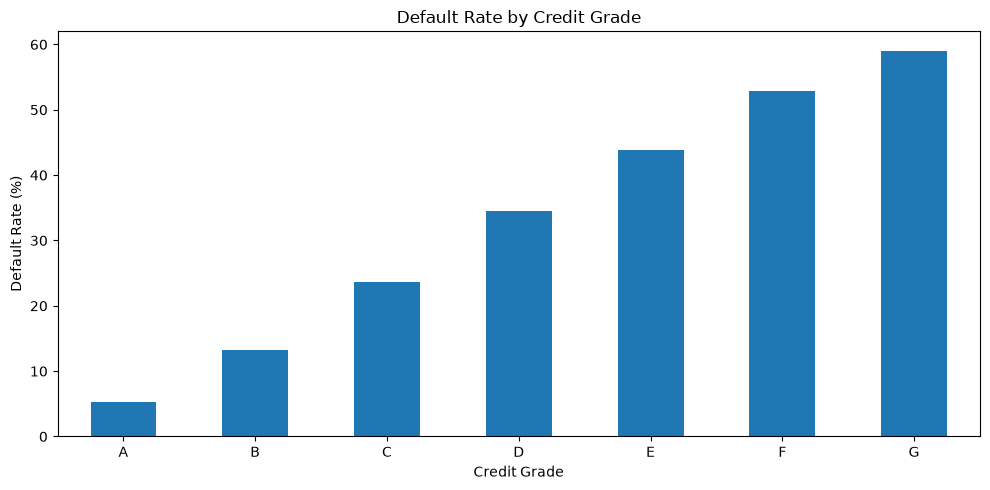

In [38]:
import matplotlib.pyplot as plt

grade_report["Default_Rate"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Default Rate by Credit Grade",
    ylabel="Default Rate (%)",
    xlabel="Credit Grade"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [40]:
resolved_loans["issue_month"] = (
    resolved_loans["issue_d"].dt.to_period("M").astype(str)
)

monthly_report = (
    resolved_loans.groupby("issue_month")
    .agg(
        Total_Loans=("id", "count"),
        Loan_Amount=("loan_amnt", "sum"),
        Default_Loans=("default_flag", "sum")
    )
)

monthly_report["Default_Rate"] = (
    monthly_report["Default_Loans"] /
    monthly_report["Total_Loans"]
) * 100

monthly_report = monthly_report.round(2)

display(monthly_report)

,Total_Loans,Loan_Amount,Default_Loans,Default_Rate
issue_month,,,,
2015-10,16133,230259375.0,2959.0,18.34
2015-11,32756,473026500.0,6508.0,19.87
2015-12,39003,560278125.0,8137.0,20.86


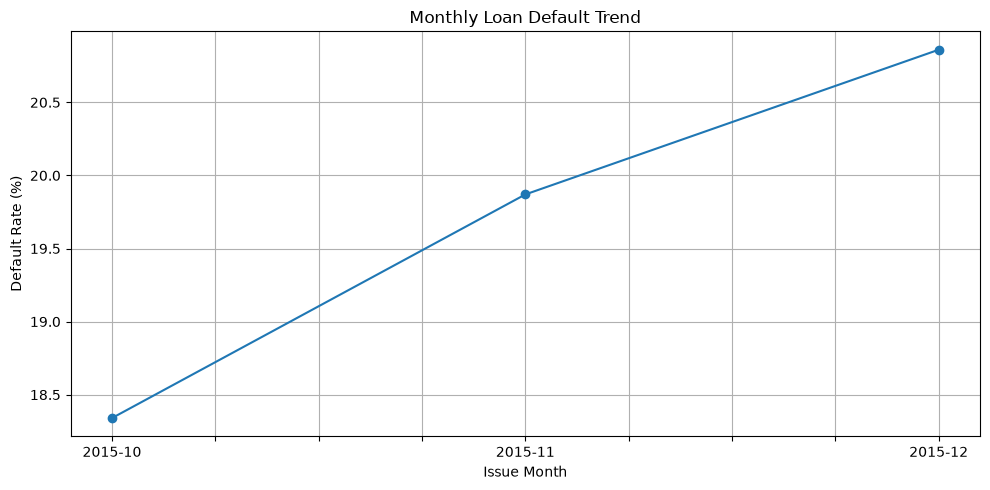

In [41]:
import matplotlib.pyplot as plt

monthly_report["Default_Rate"].plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Monthly Loan Default Trend",
    ylabel="Default Rate (%)",
    xlabel="Issue Month"
)

plt.grid(True)
plt.tight_layout()
plt.show()


In [42]:
display(monthly_report)

,Total_Loans,Loan_Amount,Default_Loans,Default_Rate
issue_month,,,,
2015-10,16133,230259375.0,2959.0,18.34
2015-11,32756,473026500.0,6508.0,19.87
2015-12,39003,560278125.0,8137.0,20.86


In [43]:
import os

os.makedirs("reports", exist_ok=True)

grade_report.to_csv(
    "reports/credit_grade_risk.csv"
)

monthly_report.to_csv(
    "reports/monthly_portfolio_trend.csv"
)

model_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Logistic Regression": [0.6601, 0.3433, 0.6891, 0.4582, 0.7369],
    "Random Forest": [0.6786, 0.3532, 0.6501, 0.4577, 0.7346]
})

model_comparison.to_csv(
    "reports/model_comparison.csv",
    index=False
)

print("All reporting files saved successfully!")

All reporting files saved successfully!


In [44]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


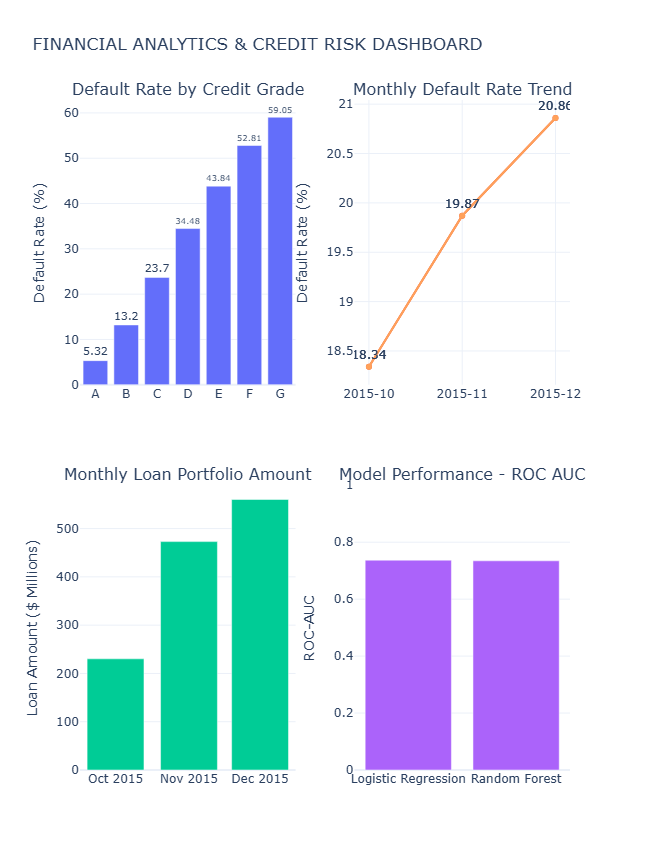

In [47]:
fig.update_xaxes(type="category", row=1, col=2)

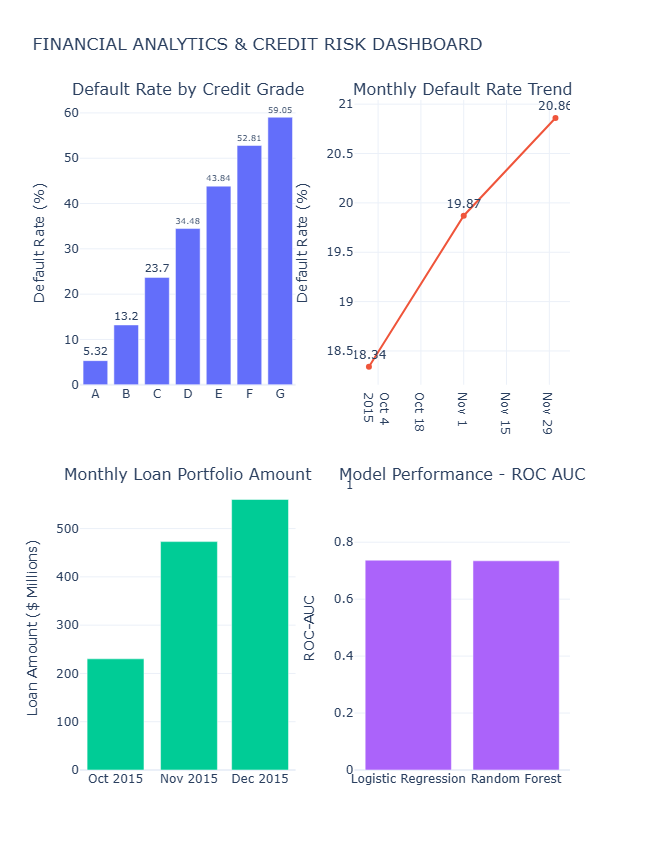

Interactive dashboard created successfully!


In [48]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=2,
    subplot_titles=(
        "Default Rate by Credit Grade",
        "Monthly Default Rate Trend",
        "Monthly Loan Portfolio Amount",
        "Model Performance - ROC AUC"
    ),
    vertical_spacing=0.15,
    horizontal_spacing=0.12
)

fig.add_trace(
    go.Bar(
        x=grade_report.index,
        y=grade_report["Default_Rate"],
        name="Default Rate (%)",
        text=grade_report["Default_Rate"].round(2),
        textposition="outside"
    ),
    row=1, col=1
)

fig.add_trace(
    go.Scatter(
        x=monthly_report.index,
        y=monthly_report["Default_Rate"],
        mode="lines+markers+text",
        text=monthly_report["Default_Rate"].round(2),
        textposition="top center",
        name="Monthly Default Rate"
    ),
    row=1, col=2
)

fig.add_trace(
    go.Bar(
        x=monthly_report.index,
        y=monthly_report["Loan_Amount"] / 1_000_000,
        name="Loan Amount ($ Millions)"
    ),
    row=2, col=1
)

fig.add_trace(
    go.Bar(
        x=["Logistic Regression", "Random Forest"],
        y=[0.7369, 0.7346],
        name="ROC-AUC"
    ),
    row=2, col=2
)

fig.update_layout(
    title="FINANCIAL ANALYTICS & CREDIT RISK DASHBOARD",
    height=850,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(title_text="Default Rate (%)", row=1, col=1)
fig.update_yaxes(title_text="Default Rate (%)", row=1, col=2)
fig.update_yaxes(title_text="Loan Amount ($ Millions)", row=2, col=1)
fig.update_yaxes(title_text="ROC-AUC", range=[0, 1], row=2, col=2)

fig.write_html("reports/financial_risk_dashboard.html")

fig.show()

print("Interactive dashboard created successfully!")

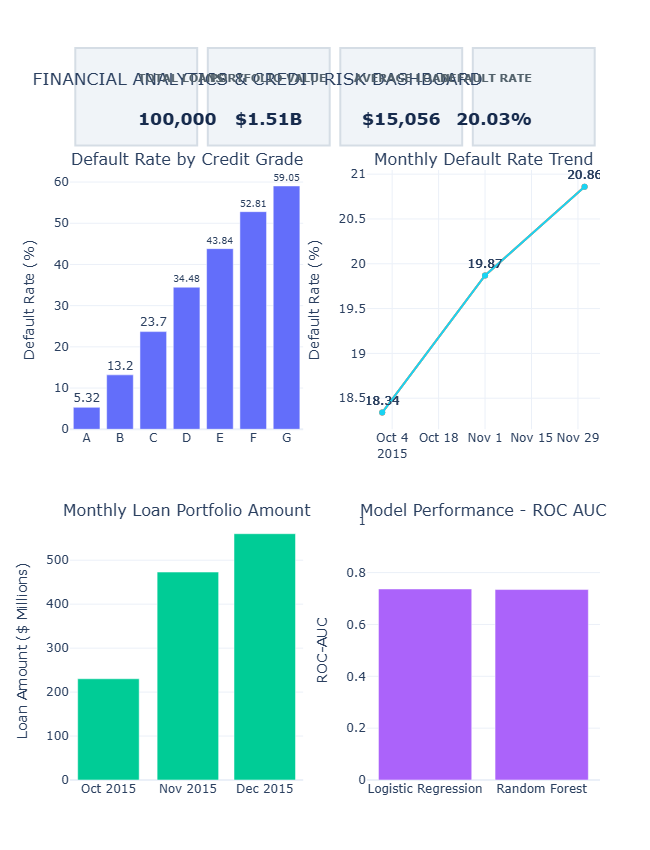

In [51]:
kpis = [
    ("TOTAL LOANS", f"{total_loans:,}"),
    ("PORTFOLIO VALUE", f"${total_loan_amount / 1e9:.2f}B"),
    ("AVERAGE LOAN", f"${average_loan_amount:,.0f}"),
    ("DEFAULT RATE", f"{default_rate:.2f}%")
]

positions = [0.125, 0.375, 0.625, 0.875]

for (label, value), x in zip(kpis, positions):

    fig.add_shape(
        type="rect",
        xref="paper", yref="paper",
        x0=x - 0.115, x1=x + 0.115,
        y0=1.04, y1=1.20,
        fillcolor="#F0F4F8",
        line=dict(color="#D5DDE5"),
        layer="below"
    )

    fig.add_annotation(
        x=x, y=1.165,
        xref="paper", yref="paper",
        text=f"<b>{label}</b>",
        showarrow=False,
        font=dict(size=11, color="#52616B")
    )

    fig.add_annotation(
        x=x, y=1.105,
        xref="paper", yref="paper",
        text=f"<b>{value}</b>",
        showarrow=False,
        font=dict(size=17, color="#172B4D")
    )

fig.update_layout(
    margin=dict(t=170, b=70, l=70, r=50)
)
fig.add_trace(
    go.Scatter(
        x=monthly_report.index.astype(str).tolist(),
        y=monthly_report["Default_Rate"],
        mode="lines+markers+text",
        text=monthly_report["Default_Rate"].round(2),
        textposition="top center",
        name="Monthly Default Rate"
    ),
    row=1, col=2
)